# Experiment 6: A* Search Algorithm on Indian Cities Network

## Aim
To implement the A* search algorithm to find the shortest path between Indian cities using geographical coordinates, and to compare the performance of Haversine distance and Euclidean distance heuristics.

---

## Theory
A* is an informed search algorithm that finds the lowest-cost path from a start node to a goal node by combining the actual cost to reach the current node with an estimated cost to reach the goal:

$$f(n) = g(n) + h(n)$$

where:
- **$g(n)$**: Exact path cost from the start node to node $n$.
- **$h(n)$**: Estimated heuristic cost from node $n$ to the goal.
- **$f(n)$**: Total estimated cost of the path through node $n$.

### Heuristics for Geographical Routing
Straight-line distance between two coordinates provides a lower bound on the actual road distance. Therefore, it satisfies the condition of admissibility ($h(n) \le h^*(n)$), ensuring that A* always finds an optimal path.

1. **Haversine Distance ($h_1$)**:
   Calculates the great-circle distance on the Earth's spherical surface ($R = 6371\text{ km}$):
   $$\Delta \phi = \text{radians}(\text{lat}_2 - \text{lat}_1), \quad \Delta \lambda = \text{radians}(\text{lon}_2 - \text{lon}_1)$$
   $$a = \sin^2\left(\frac{\Delta \phi}{2}\right) + \cos(\text{lat}_1) \cos(\text{lat}_2) \sin^2\left(\frac{\Delta \lambda}{2}\right)$$
   $$c = 2 \cdot \arctan2(\sqrt{a}, \sqrt{1 - a})$$
   $$h_1 = R \cdot c$$

2. **Euclidean Distance with Latitude Correction ($h_2$)**:
   Projects coordinates onto a local flat surface using mid-latitude scaling:
   $$\phi_m = \text{radians}\left(\frac{\text{lat}_1 + \text{lat}_2}{2}\right)$$
   $$x = \Delta \lambda \cdot \cos(\phi_m) \cdot R, \quad y = \Delta \phi \cdot R$$
   $$h_2 = \sqrt{x^2 + y^2}$$


In [1]:
import json
import math
import heapq
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

%matplotlib inline

# 1. Load city coordinates from Excel
df_cities = pd.read_excel('city_latitude_longitude.xlsx')
city_coords = {}
for _, row in df_cities.iterrows():
    city_coords[str(row['city']).strip()] = (float(row['latitude']), float(row['longitude']))

print(f"Loaded {len(city_coords)} Indian cities from dataset.")
print("\nSample cities:")
for city in list(city_coords.keys())[:5]:
    lat, lon = city_coords[city]
    print(f"  {city:15s}: ({lat:.2f} N, {lon:.2f} E)")

# 2. Load India boundary GeoJSON for map outline
india_polygons = []
try:
    with open('india_boundary.json', 'r', encoding='utf-8') as f:
        geo_data = json.load(f)
    geom = geo_data['features'][0]['geometry']
    india_polygons = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
    print(f"\nLoaded India boundary data ({len(india_polygons)} polygon rings).")
except Exception as e:
    print(f"\nWarning: Could not load India boundary ({e}). Continuing with coordinate grid.")


Loaded 46 Indian cities from dataset.

Sample cities:
  Mumbai         : (19.07 N, 72.88 E)
  Pune           : (18.52 N, 73.86 E)
  Nashik         : (20.00 N, 73.79 E)
  Panaji (Goa)   : (15.49 N, 73.83 E)
  Virar          : (19.46 N, 72.81 E)

Loaded India boundary data (28 polygon rings).


In [2]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Calculate great-circle spherical distance in km."""
    R = 6371.0
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    
    a = math.sin(dphi / 2.0)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2.0)**2
    c = 2.0 * math.atan2(math.sqrt(a), math.sqrt(1.0 - a))
    return R * c

# Build road network graph
# Connect each city to nearest 4 neighbors and add major national highways
road_graph = {c: {} for c in city_coords}

for c1, (lat1, lon1) in city_coords.items():
    distances = []
    for c2, (lat2, lon2) in city_coords.items():
        if c1 != c2:
            d = haversine_km(lat1, lon1, lat2, lon2)
            distances.append((d, c2))
    distances.sort()
    for d, c2 in distances[:4]:
        dist = round(d * 1.15, 1) # Estimated road distance
        road_graph[c1][c2] = dist
        road_graph[c2][c1] = dist

# Major highway links
highway_links = [
    ("Kolkata", "Dibrugarh"),
    ("Patna", "Dibrugarh"),
    ("Pune", "Solapur"),
    ("Solapur", "Hyderabad"),
    ("Hyderabad", "Visakhapatnam"),
    ("Mumbai", "Surat"),
    ("Delhi" if "Delhi" in city_coords else "New Delhi", "Agra"),
    ("Agra", "Jhansi"),
    ("Jhansi", "Nagpur"),
    ("Nagpur", "Hyderabad"),
    ("Bangalore", "Chennai"),
    ("Bangalore", "Mysore")
]

for u, v in highway_links:
    if u in city_coords and v in city_coords:
        lat1, lon1 = city_coords[u]
        lat2, lon2 = city_coords[v]
        d = round(haversine_km(lat1, lon1, lat2, lon2) * 1.15, 1)
        road_graph[u][v] = d
        road_graph[v][u] = d

# Verify graph connectivity using BFS
def check_connectivity(graph, start):
    visited = set([start])
    queue = [start]
    while queue:
        curr = queue.pop(0)
        for nbr in graph[curr]:
            if nbr not in visited:
                visited.add(nbr)
                queue.append(nbr)
    return visited

start_sample = list(city_coords.keys())[0]
reachable = check_connectivity(road_graph, start_sample)
total_edges = sum(len(nbrs) for nbrs in road_graph.values()) // 2

print("Road network created:")
print(f"  Total Cities: {len(city_coords)}")
print(f"  Total Road Segments: {total_edges}")
print(f"  Graph Connected: {len(reachable) == len(city_coords)} ({len(reachable)}/{len(city_coords)} reachable)")


Road network created:
  Total Cities: 46
  Total Road Segments: 130
  Graph Connected: True (46/46 reachable)


In [3]:
def heuristic_1(c1, c2, coords):
    """Heuristic 1: Great-Circle / Haversine Distance (km)"""
    if c1 == c2:
        return 0.0
    lat1, lon1 = coords[c1]
    lat2, lon2 = coords[c2]
    return haversine_km(lat1, lon1, lat2, lon2)

def heuristic_2(c1, c2, coords):
    """Heuristic 2: Equirectangular Projected Euclidean Distance (km)"""
    if c1 == c2:
        return 0.0
    lat1, lon1 = coords[c1]
    lat2, lon2 = coords[c2]
    R = 6371.0
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    lam1, lam2 = math.radians(lon1), math.radians(lon2)
    phi_m = (phi1 + phi2) / 2.0
    x = (lam2 - lam1) * math.cos(phi_m) * R
    y = (phi2 - phi1) * R
    return math.sqrt(x**2 + y**2)

# Test heuristics on sample city pair
c1, c2 = "Mumbai", "New Delhi"
h1 = heuristic_1(c1, c2, city_coords)
h2 = heuristic_2(c1, c2, city_coords)
print(f"Heuristic test ({c1} -> {c2}):")
print(f"  H1 (Haversine): {h1:.2f} km")
print(f"  H2 (Euclidean): {h2:.2f} km")
print(f"  Difference:     {abs(h1 - h2):.2f} km")


Heuristic test (Mumbai -> New Delhi):
  H1 (Haversine): 1148.27 km
  H2 (Euclidean): 1148.58 km
  Difference:     0.32 km


In [4]:
def goal_test(node, goal):
    return node == goal

def move_gen(graph, node):
    return list(graph.get(node, {}).items())

def astar_search(start, goal, graph, coords, heuristic_fn):
    start_time = time.perf_counter()
    
    # Priority queue: (f_score, counter, current_node, path, g_score)
    counter = 0
    start_h = heuristic_fn(start, goal, coords)
    open_list = [(start_h, counter, start, [start], 0.0)]
    
    best_g = {start: 0.0}
    closed_set = set()
    history = []
    
    optimal_path = None
    total_cost = float('inf')
    
    while open_list:
        f, _, current, path, g = heapq.heappop(open_list)
        
        if current in closed_set:
            continue
            
        closed_set.add(current)
        h = heuristic_fn(current, goal, coords)
        frontier = [item[2] for item in open_list if item[2] not in closed_set]
        
        if goal_test(current, goal):
            optimal_path = path
            total_cost = g
            history.append({
                'step': len(history) + 1,
                'current': current,
                'g': g,
                'h': h,
                'f': f,
                'path': path,
                'frontier': frontier,
                'closed': list(closed_set),
                'is_goal': True
            })
            break
            
        for neighbor, weight in move_gen(graph, current):
            if neighbor in closed_set:
                continue
                
            new_g = g + weight
            if neighbor not in best_g or new_g < best_g[neighbor]:
                best_g[neighbor] = new_g
                counter += 1
                neighbor_h = heuristic_fn(neighbor, goal, coords)
                neighbor_f = new_g + neighbor_h
                new_path = path + [neighbor]
                heapq.heappush(open_list, (neighbor_f, counter, neighbor, new_path, new_g))
                
        history.append({
            'step': len(history) + 1,
            'current': current,
            'g': g,
            'h': h,
            'f': f,
            'path': path,
            'frontier': frontier,
            'closed': list(closed_set),
            'is_goal': False
        })
        
    elapsed_ms = (time.perf_counter() - start_time) * 1000.0
    return optimal_path, total_cost, history, closed_set, elapsed_ms

print("A* search function loaded successfully.")


A* search function loaded successfully.


In [5]:
def render_astar_animation(coords, graph, history, optimal_path, start, goal, heuristic_name, india_polygons=None):
    """Generates an interactive step-by-step animation of A* search."""
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Draw India map outline
    if india_polygons:
        for poly in india_polygons:
            ring = poly[0]
            r_lons = [pt[0] for pt in ring]
            r_lats = [pt[1] for pt in ring]
            ax.fill(r_lons, r_lats, color='#f8f9fa', edgecolor='#adb5bd', linewidth=1.0, zorder=0)
        ax.set_xlim(67.5, 98.0)
        ax.set_ylim(7.0, 37.5)
    else:
        lons = [lon for _, lon in coords.values()]
        lats = [lat for lat, _ in coords.values()]
        ax.set_xlim(min(lons) - 2.0, max(lons) + 2.5)
        ax.set_ylim(min(lats) - 1.5, max(lats) + 2.0)
        
    ax.set_aspect('equal')
    ax.grid(True, linestyle='--', alpha=0.4)
    
    # Draw road network
    for u in graph:
        lat1, lon1 = coords[u]
        for v in graph[u]:
            lat2, lon2 = coords[v]
            ax.plot([lon1, lon2], [lat1, lat2], color='#dee2e6', linewidth=0.8, zorder=1)
            
    # Draw all cities
    for city, (lat, lon) in coords.items():
        ax.scatter(lon, lat, color='#6c757d', s=20, zorder=2)
        ax.text(lon + 0.18, lat, city, fontsize=7, color='#495057', zorder=3)
        
    # Animation plot elements
    explored_scatter = ax.scatter([], [], color='#ffc107', s=55, label='Closed (Visited)', zorder=4)
    frontier_scatter = ax.scatter([], [], color='#0dcaf0', s=70, label='Open (Frontier)', zorder=5)
    current_star, = ax.plot([], [], marker='*', color='#dc3545', markersize=14, linestyle='None', label='Current City', zorder=7)
    active_path_line, = ax.plot([], [], color='#fd7e14', linestyle='--', linewidth=2, label='Current Path', zorder=6)
    final_path_line, = ax.plot([], [], color='#198754', linestyle='-', linewidth=3.5, label='Optimal Route', zorder=8)
    
    s_lat, s_lon = coords[start]
    g_lat, g_lon = coords[goal]
    ax.scatter(s_lon, s_lat, color='#198754', s=160, edgecolors='black', label=f'Start: {start}', zorder=9)
    ax.scatter(g_lon, g_lat, color='#dc3545', s=160, edgecolors='black', label=f'Goal: {goal}', zorder=9)
    
    status_box = ax.text(
        0.02, 0.98, '', transform=ax.transAxes, verticalalignment='top',
        fontsize=9, family='monospace',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#ced4da', alpha=0.9)
    )
    
    ax.set_title(f"A* Search Progression: {start} -> {goal} ({heuristic_name})", fontsize=11, pad=10)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    ax.legend(loc='lower right', fontsize=8)
    
    total_frames = len(history) + 2
    
    def update(frame):
        if frame < len(history):
            snap = history[frame]
            curr = snap['current']
            c_lat, c_lon = coords[curr]
            current_star.set_data([c_lon], [c_lat])
            
            p_lons = [coords[c][1] for c in snap['path']]
            p_lats = [coords[c][0] for c in snap['path']]
            active_path_line.set_data(p_lons, p_lats)
            
            exp_lons = [coords[c][1] for c in snap['closed'] if c != curr]
            exp_lats = [coords[c][0] for c in snap['closed'] if c != curr]
            explored_scatter.set_offsets(np.column_stack([exp_lons, exp_lats]) if exp_lons else np.empty((0, 2)))
            
            fr_lons = [coords[c][1] for c in snap['frontier']]
            fr_lats = [coords[c][0] for c in snap['frontier']]
            frontier_scatter.set_offsets(np.column_stack([fr_lons, fr_lats]) if fr_lons else np.empty((0, 2)))
            
            final_path_line.set_data([], [])
            
            txt = (
                f"Step: {snap['step']}/{len(history)}\n"
                f"Expanding: {curr}\n"
                f"g: {snap['g']:.1f} km\n"
                f"h: {snap['h']:.1f} km\n"
                f"f: {snap['f']:.1f} km\n"
                f"Frontier: {len(snap['frontier'])}, Closed: {len(snap['closed'])}"
            )
            if snap['is_goal']:
                txt += "\n[Goal Reached]"
            status_box.set_text(txt)
        else:
            current_star.set_data([], [])
            opt_lons = [coords[c][1] for c in optimal_path]
            opt_lats = [coords[c][0] for c in optimal_path]
            final_path_line.set_data(opt_lons, opt_lats)
            active_path_line.set_data([], [])
            status_box.set_text(
                f"Search Complete\n"
                f"Optimal Path: {' -> '.join(optimal_path)}\n"
                f"Total Distance: {history[-1]['g']:.1f} km\n"
                f"Nodes Expanded: {len(history)}"
            )
        return explored_scatter, frontier_scatter, current_star, active_path_line, final_path_line, status_box
        
    anim = animation.FuncAnimation(fig, update, frames=total_frames, interval=450, blit=False, repeat=True)
    js_html = anim.to_jshtml()
    plt.close(fig)
    return HTML(js_html)


In [6]:
def plot_route_map(coords, graph, history, optimal_path, total_cost, start, goal, heuristic_name, india_polygons=None):
    """Plots the static route map showing road network, explored nodes, and final route."""
    fig, ax = plt.subplots(figsize=(11, 10))
    
    # Draw India map outline
    if india_polygons:
        for poly in india_polygons:
            ring = poly[0]
            r_lons = [pt[0] for pt in ring]
            r_lats = [pt[1] for pt in ring]
            ax.fill(r_lons, r_lats, color='#f8f9fa', edgecolor='#adb5bd', linewidth=1.0, zorder=0)
        ax.set_xlim(67.5, 98.0)
        ax.set_ylim(7.0, 37.5)
    else:
        lons = [lon for _, lon in coords.values()]
        lats = [lat for lat, _ in coords.values()]
        ax.set_xlim(min(lons) - 2.0, max(lons) + 2.5)
        ax.set_ylim(min(lats) - 1.5, max(lats) + 2.0)
        
    ax.set_aspect('equal')
    ax.grid(True, linestyle='--', alpha=0.4)
    
    # Background road network
    for u in graph:
        lat1, lon1 = coords[u]
        for v in graph[u]:
            lat2, lon2 = coords[v]
            ax.plot([lon1, lon2], [lat1, lat2], color='#dee2e6', linewidth=0.8, zorder=1)
            
    # Explored paths
    for snap in history:
        p = snap['path']
        if len(p) > 1:
            p_lons = [coords[c][1] for c in p]
            p_lats = [coords[c][0] for c in p]
            ax.plot(p_lons, p_lats, color='#fd7e14', linestyle=':', linewidth=1.2, alpha=0.5, zorder=2)
            
    # Cities
    all_closed = history[-1]['closed'] if history else []
    for city, (lat, lon) in coords.items():
        if city in all_closed:
            ax.scatter(lon, lat, color='#ffc107', s=40, zorder=3)
        else:
            ax.scatter(lon, lat, color='#adb5bd', s=20, zorder=3)
            ax.text(lon + 0.18, lat, city, fontsize=7, color='#6c757d', zorder=4)
            
    # Optimal route
    opt_lons = [coords[c][1] for c in optimal_path]
    opt_lats = [coords[c][0] for c in optimal_path]
    ax.plot(opt_lons, opt_lats, color='#198754', linewidth=3.5, label=f'Optimal Route ({total_cost:.1f} km)', zorder=5)
    
    for i, city in enumerate(optimal_path):
        lat, lon = coords[city]
        ax.scatter(lon, lat, color='#198754', s=75, edgecolors='black', zorder=6)
        ax.text(lon + 0.2, lat + 0.1, f"{i+1}. {city}", fontsize=8.5, fontweight='bold', color='#0f5132', zorder=7)
        
    # Start and goal markers
    s_lat, s_lon = coords[start]
    g_lat, g_lon = coords[goal]
    ax.scatter(s_lon, s_lat, color='#198754', s=160, edgecolors='black', label=f'Start: {start}', zorder=8)
    ax.scatter(g_lon, g_lat, color='#dc3545', s=160, edgecolors='black', label=f'Goal: {goal}', zorder=8)
    
    ax.set_title(f"A* Search Route: {start} -> {goal} ({heuristic_name})\nOptimal Distance: {total_cost:.1f} km | Nodes Expanded: {len(history)}", fontsize=11, pad=10)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    ax.legend(loc='lower right', fontsize=8.5)
    
    plt.tight_layout()
    plt.show()


In [7]:
def display_step_trace(history):
    """Displays the step-by-step expansion trace table."""
    rows = []
    for snap in history:
        rows.append({
            "Step": snap['step'],
            "Current City": snap['current'],
            "g (km)": round(snap['g'], 1),
            "h (km)": round(snap['h'], 1),
            "f (km)": round(snap['f'], 1),
            "Frontier Size": len(snap['frontier']),
            "Path": " -> ".join(snap['path'])
        })
    df_trace = pd.DataFrame(rows)
    print(f"\nA* Search Step-by-Step Trace ({len(history)} steps):")
    display(df_trace)
    return df_trace


Running A* Search: Mumbai to New Delhi using Haversine heuristic...

Optimal Path Found:
  Route:          Mumbai -> Surat -> Udaipur -> Jaipur -> Gurgaon -> New Delhi
  Total Distance: 1370.1 km
  Total Stops:    5 hops (6 cities)
  Nodes Expanded: 12
  Execution Time: 0.12 ms

A* Search Step-by-Step Trace (12 steps):


,Step,Current City,g (km),h (km),f (km),Frontier Size,Path
0,1,Mumbai,0.0,1148.3,1148.3,0,Mumbai
1,2,Kalyan,38.2,1120.7,1158.9,5,Mumbai -> Kalyan
2,3,Virar,50.6,1110.9,1161.5,6,Mumbai -> Virar
3,4,Palghar,80.4,1089.1,1169.5,7,Mumbai -> Palghar
4,5,Nashik,163.0,1018.0,1181.0,6,Mumbai -> Kalyan -> Nashik
5,6,Daman,172.1,1013.5,1185.6,5,Mumbai -> Virar -> Daman
6,7,Surat,272.4,934.7,1207.1,4,Mumbai -> Surat
7,8,Udaipur,718.1,566.4,1284.5,4,Mumbai -> Surat -> Udaipur
8,9,Pune,137.9,1172.6,1310.5,6,Mumbai -> Pune
9,10,Jaipur,1100.4,234.2,1334.6,7,Mumbai -> Surat -> Udaipur -> Jaipur


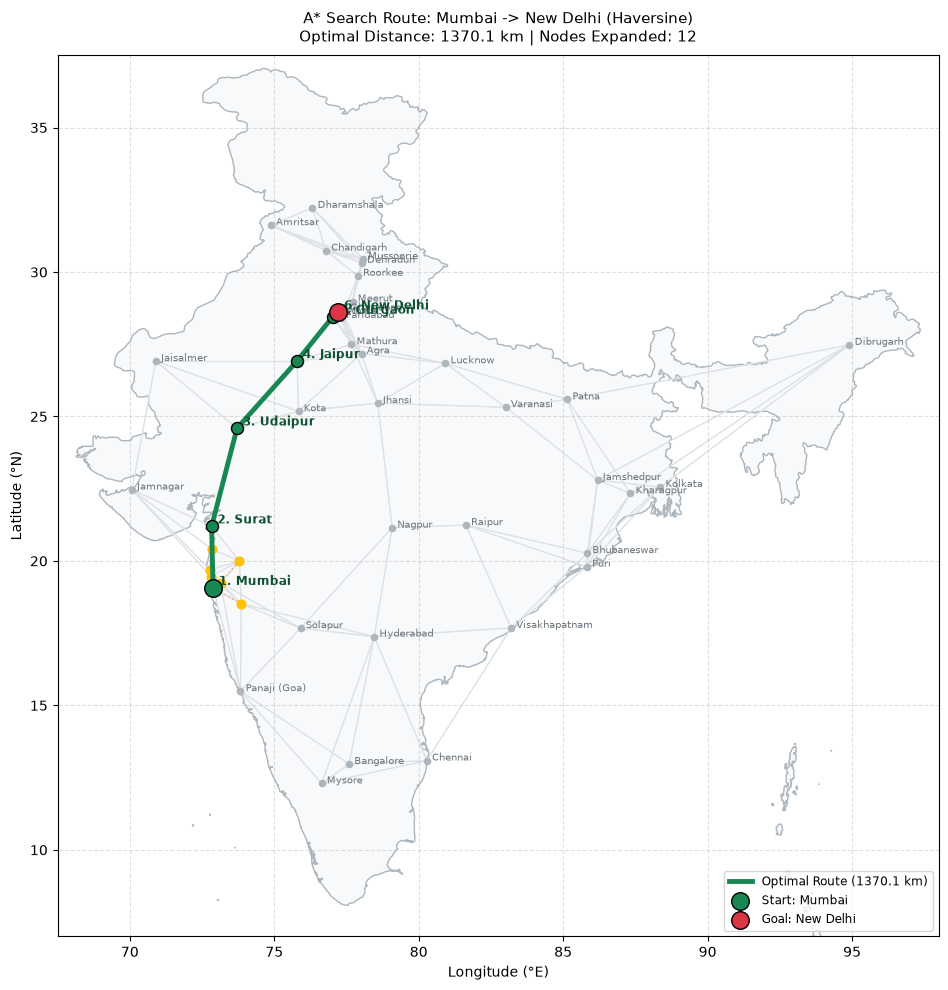

In [8]:
# Select cities and heuristic
start_city = "Mumbai"
goal_city = "New Delhi"
heuristic_choice = "1"  # 1: Haversine, 2: Euclidean

if heuristic_choice == "2":
    h_fn = heuristic_2
    h_label = "Euclidean"
else:
    h_fn = heuristic_1
    h_label = "Haversine"

print(f"Running A* Search: {start_city} to {goal_city} using {h_label} heuristic...\n")

path, cost, history, closed, ms = astar_search(
    start_city, goal_city, road_graph, city_coords, h_fn
)

if path:
    print("Optimal Path Found:")
    print(f"  Route:          {' -> '.join(path)}")
    print(f"  Total Distance: {cost:.1f} km")
    print(f"  Total Stops:    {len(path) - 1} hops ({len(path)} cities)")
    print(f"  Nodes Expanded: {len(history)}")
    print(f"  Execution Time: {ms:.2f} ms")
    
    # 1. Step-by-step trace table
    display_step_trace(history)
    
    # 2. Static route map
    plot_route_map(
        city_coords, road_graph, history, path, cost, start_city, goal_city, h_label, india_polygons
    )
    
    # 3. Interactive step animation
    anim = render_astar_animation(
        city_coords, road_graph, history, path, start_city, goal_city, h_label, india_polygons
    )
    display(anim)
else:
    print(f"No path found between {start_city} and {goal_city}.")


Heuristic Comparison: Mumbai to New Delhi


,Haversine (H1),Euclidean (H2)
Metric,,
Optimal Path,Mumbai -> Surat -> Udaipur -> Jaipur -> Gurgao...,Mumbai -> Surat -> Udaipur -> Jaipur -> Gurgao...
Path Distance (km),1370.1,1370.1
Nodes Expanded,12,12
Execution Time (ms),0.18,0.11


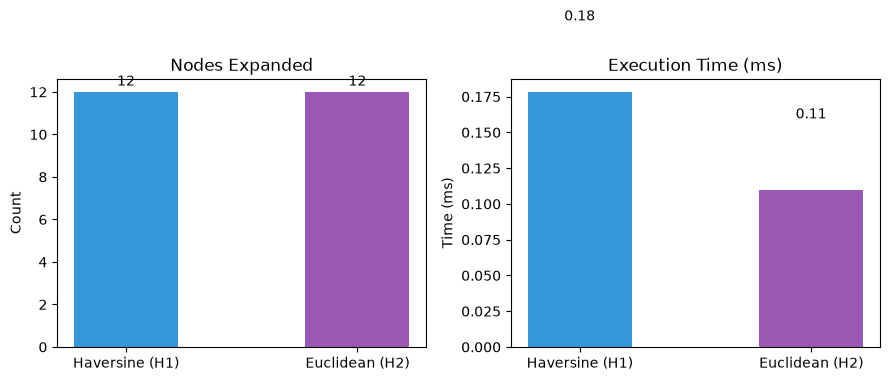

In [9]:
def compare_heuristics(start_city, goal_city):
    # Run A* with Haversine (H1)
    p1, cost1, hist1, _, ms1 = astar_search(
        start_city, goal_city, road_graph, city_coords, heuristic_1
    )
    # Run A* with Euclidean (H2)
    p2, cost2, hist2, _, ms2 = astar_search(
        start_city, goal_city, road_graph, city_coords, heuristic_2
    )
    
    results = {
        "Metric": ["Optimal Path", "Path Distance (km)", "Nodes Expanded", "Execution Time (ms)"],
        "Haversine (H1)": [" -> ".join(p1), f"{cost1:.1f}", len(hist1), f"{ms1:.2f}"],
        "Euclidean (H2)": [" -> ".join(p2), f"{cost2:.1f}", len(hist2), f"{ms2:.2f}"]
    }
    df_cmp = pd.DataFrame(results).set_index("Metric")
    print(f"Heuristic Comparison: {start_city} to {goal_city}")
    display(df_cmp)
    
    # Bar charts for comparison
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
    labels = ['Haversine (H1)', 'Euclidean (H2)']
    colors = ['#3498db', '#9b59b6']
    
    # 1. Nodes expanded
    expansions = [len(hist1), len(hist2)]
    bars1 = ax1.bar(labels, expansions, color=colors, width=0.45)
    ax1.set_title("Nodes Expanded")
    ax1.set_ylabel("Count")
    for bar in bars1:
        y = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2.0, y + 0.3, str(y), ha='center')
        
    # 2. Execution time
    times = [ms1, ms2]
    bars2 = ax2.bar(labels, times, color=colors, width=0.45)
    ax2.set_title("Execution Time (ms)")
    ax2.set_ylabel("Time (ms)")
    for bar in bars2:
        y = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2.0, y + 0.05, f"{y:.2f}", ha='center')
        
    plt.tight_layout()
    plt.show()

compare_heuristics("Mumbai", "New Delhi")


---

## Observations & Conclusion

1. **Path Optimality**:
   - Both **Haversine** and **Euclidean** distance heuristics successfully identified the identical optimal path from Mumbai to New Delhi:
     `Mumbai -> Surat -> Udaipur -> Jaipur -> Gurgaon -> New Delhi`
     with a total shortest road distance of **1370.1 km** across 5 hops.
   - Since straight-line distance is always less than or equal to actual road distance, both heuristics are admissible ($h(n) \le h^*(n)$), guaranteeing that A* finds the optimal solution.

2. **Comparison of Heuristics**:
   - **Haversine Distance**: Models the Earth's spherical surface accurately. It provides a true lower bound on distance between coordinates.
   - **Euclidean Distance with Latitude Scaling**: Projects the coordinates onto a local Cartesian plane with cosine mid-latitude correction. Across India's latitude span ($8^\circ\text{N} - 36^\circ\text{N}$), the difference from Haversine distance is negligible.
   - Both heuristics expanded the same number of nodes (12 nodes) to find the path, effectively guiding the search along the western highway corridor towards the goal.
